# 07 · 随机森林特征重要性

重要性反映模型在历史数据中使用某变量区分订购结果的程度，不代表因果关系。

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists(): PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.models import build_preprocessor

train = pd.read_csv(PROJECT_ROOT / 'data/processed/train_precall.csv')
X_train, y_train = train.drop(columns='target_subscription'), train['target_subscription']
preprocessor = build_preprocessor(X_train)
model = Pipeline([('preprocessor', preprocessor), ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample', n_jobs=-1, random_state=42))])
_ = model.fit(X_train, y_train)

In [2]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()
importance = model.named_steps['model'].feature_importances_
encoded_importance = pd.DataFrame({'encoded_feature': feature_names, 'importance': importance})

numeric = X_train.select_dtypes(include='number').columns.tolist()
categorical = X_train.select_dtypes(include=['object', 'string']).columns.tolist()
def original_variable(name):
    if name.startswith('numeric__'):
        return name.removeprefix('numeric__')
    for column in categorical:
        if name.startswith(f'categorical__{column}_'):
            return column
    return name

encoded_importance['variable'] = encoded_importance['encoded_feature'].map(original_variable)
variable_importance = encoded_importance.groupby('variable', as_index=False)['importance'].sum().sort_values('importance', ascending=False)
variable_importance.to_csv(PROJECT_ROOT / 'reports/feature_importance.csv', index=False)
display(variable_importance.head(15).style.format({'importance':'{:.2%}'}))

,variable,importance
10,euribor3m,14.41%
16,nr.employed,9.82%
0,age,8.08%
9,emp.var.rate,7.53%
13,job,6.34%
6,day_of_week,5.78%
8,education,5.73%
2,campaign,4.85%
18,poutcome,4.71%
15,month,4.42%


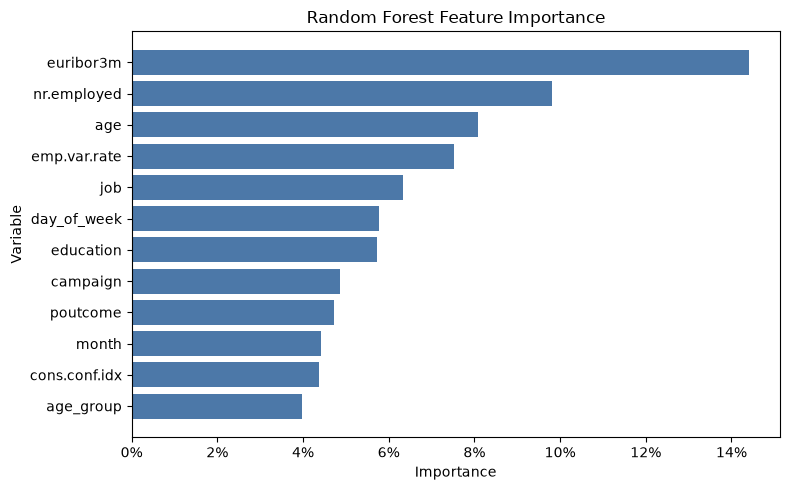

In [3]:
top = variable_importance.head(12).sort_values('importance')
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top['variable'], top['importance'], color='#4C78A8')
ax.set(title='Random Forest Feature Importance', xlabel='Importance', ylabel='Variable')
ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
fig.tight_layout()
fig.savefig(PROJECT_ROOT / 'figures/modeling/feature_importance.png', dpi=160, bbox_inches='tight')
plt.show()

## 业务解读

优先将可行动的高重要性变量（既往营销结果、联系渠道、月份）用于客群筛选和活动设计；年龄、职业等用于辅助分层，不应单独决定是否联系客户。